In [1]:
# Homework 3: Root ﬁnding
# Due Nov. 12
# Alex Feucht
# ASTR 427 - Professor Quinn Fall 2026 UW Seattle Campus
#
# AI Disclosure:
# Claude/Gemini search engine results used for general debugging and querying of 
# python package documentation/syntax, no generative uses permitted.

In [2]:
# Imports/Packages

%pip install autograd # forgot to include, wrongly assumed default kernel had it
import autograd.numpy as np # auto-grad multi-dimensional solver, Newton uses
from autograd import grad
from autograd import jacobian
import autograd.numpy as anp # alt autograd for anp.sin instead of math.sin

import scipy.optimize as opt # scipy package dependencies
from scipy.optimize import brentq # for analytic curve for Kepler plotting
from scipy.integrate import quad # using on problem #3 for integration

import matplotlib.pyplot as plt # plotting

from functools import partial # Used for lambda handling for +-sqrt(a) values
import sys # Machine precision limit references to validate convergence
eps = sys.float_info.epsilon # FP e(m) epsilon precision, min representable val.
import time # wall clock requires
import math # more efficient math.sin method, over anp.sin

In [3]:
# 1. Write a program to ﬁnd the roots of one-dimensional equations using 
# a) Bisection method, and 
# b) Newton-Raphson method. 
# For the Newton-Raphson method, keep the root bracketed as recommended in class
# Test your implementations on the following equations:

# (a) A simple test case: x^2 = a 
# (choose an a, say 2.0, and solve for (positive) x).

# (b) Kepler’s equation, used for determining Solar System orbits:
# M = E − e * sin(E).

# Here M is the “mean anomoly”, an angle that increases linearly in time; 
# E is the “eccentric anomoly”, the position of the body from
# the center (not the focus) of the ellipse, and e is the eccentricity
# of the ellipse. 

# Choose M = 1.5 and e = 0.5 and solve for E in the interval 0 ≤ E < 2π. 
# Try it again for M = 1.5 and e = 0.9, but be careful where you start the 
# Newton-Raphson.

# For each attempt, demonstrate how quickly the method converges by
# plotting the error (i.e., the diﬀerence between the current guess and
# the true answer) as a function of iteration number. 
# I suggest using a logarithmic axis for the error.

In [4]:
# Bisection Method Declaration:

# For F(a), F(b) bracketing a zero, eval. F(a) * F(b) < 0 as initial bound check
# Midpoint M = (b-a)/2, becomes new F(M) evaluation
# eval. F(a) * F(M) < 0, if true = new brackets, if false use b to M interval
# eval. F(b) * F(M) < 0, true = new bracket, replace prior brackets.
# If F(a or b) * F(M) > 0, never converges, not bracketing around a root
# Run recursively, converges unless there is a discontinuity for function,
# or if there is a constant line, periodic, a local peak, bad brackets, etc...
# Every factor of 2 = bit of precision added to mantissa, per bisection.
# Double precision requires > ~60 steps, float > ~23 steps, will have round-off
# of that order of precision still.

# Bisection Method:

# Accepts function, initial (a, b) guesses around root, iterations to run
def Bisection(Funct, a, b, max_iteration1):
    Fa, Fb = Funct(a), Funct(b) # variable assign for function eval. at brackets
    
    if a > b:
        a, b = b, a # flips order, assumes ascending order always for plotting
    if a == b: # error handling for zero distance brackets
        raise ValueError("a and b must be different values")
    if Fa * Fb > 0: # Negative values required for convergence per iteration
        raise ValueError("a and b do not bracket root, need opposite signs")
    if Fa == 0: # Trivial cases handling bracket being on a root, for a or b
        return a, 1
    if Fb == 0:
        return b, 1

    history = [] # keeps array of values of towards convergence at index
    for i in range(max_iteration1): # recursive until double precision >60 iter.
        M = a + (b - a) / 2.0 # assign midpoint 
        FM = Funct(M) # eval. function at midpoint
        history.append(M) # tabulate midpoints at each indexed step

        # In precision limits, midpoint would minimally be between 2 FP with no
        # intermediate value, if the function at the midpoint is 0.0 exactly,
        # or either of the brackets becomes equal to the midpoint exactly
        # to machine precision limits, it will halt and return the midpoint
        # as a root of the function - should scale more dynamically than
        # hard-coded tolerance intervals. Still requires sufficient iterations
        # to meet the wanted precision limits, safe bet for doubles/floats >~60
        
        if FM == 0.0 or M == a or M == b: # root checks for brackets, F(M) = 0.0
            return M, i, history # Midpoint becomes root in all 3 cases
        if Fa * FM < 0.0: # checks for negative, valid bracketing if true
            b, Fb = M, FM # set b, F(b) to the prior midpoint if (a, M) valid
        else: # if bracket not between (a, M), use (M, b) instead, set a -> M
            a, Fa = M, FM # This reassignment lets it run recursively
            
    return M, i, history # outputs midpoint vals, index at sol, history converge

In [5]:
# Newton-Raphson Method Declaration:

# Requires arbitrary derivative helper function (hard-coded, or AutoGrad for #2)
# Tuning h to be higher order of estimate error term, of order O(h^3)
# (machine precision)^1/3 * scaling factor relative to x & not lower than 1.0

def Derivative(F, x): # Takes passed func inside of Newton-Raphson, x value
    h = eps**(1/3) * max(abs(x), 1.0) # scaled error term e(m)^1/3 from lecture
    return ((F(x + h) - F(x - h)) / (2.0 * h)) # Central Difference err ~O(h^2)
    # returns F'(x) derivative/tangent slope at x

# Newton-Raphson Accepts arbitrary function, arbitrary x starting value, need 
# convergent guess. If tangent derivative slope of x_arb does not converge to a 
# root, either the funct is discontinuous, periodic/oscillatory, has a 
# multiplicitity at the root, is a constant horizontal line, etc.

# x_(n+1) = x_n - (F(x_n) / F'(x_n)) : iterate until precision limits are hit
# Function F evaluated at arbitrary x, divided by derivative of same F(x), F'(x)
# subtracted from given initial x value, gives next iteration step.
# Function kick-starts from given function, initial x, uses derived step to
# form a slope between two points and evals that recursively until root reached

# Newton-Raphson Method: - Hard-coded, non-AutoGrad 

# Takes params for arbitrary function, arbitrary x, and max iterations to run
def NewtonRaphson(Funct, x_arb, max_iteration2):
    x = x_arb
    historyNR = [x] # keeps array of values of towards convergence at index
    dx_prev = np.inf # holds previous dx val for plotting to last point
    # otherwise last point will not be on e(m) convergent precision limit
    # and the line is discontinuous, even if the point is still plotted
    
    for j in range(max_iteration2): # main loop over selected # of iterations
        Fx = Funct(x)
        if Fx == 0.0:
            return x, j, historyNR # returns found root solution, iter, history
            
        Fprime = Derivative(Funct, x) # calls derivative helper function
        if Fprime == 0.0: # zero slope derivative from listed non-convergences
            raise ZeroDivisionError("Zero Slope, starting x won't converge")

        dx = Fx / Fprime # setting F(x)/F'(x) term
        x_update = x - dx # x_n - (F(x_n) / F'(x_n)) 
        historyNR.append(x_update) # appends convergence array per iteration.

        # strict test, OR at the noise floor (step tiny and no longer shrinking)
        at_floor = \
        abs(dx) >= abs(dx_prev) and abs(dx) < 1e-6 * max(abs(x_update), 1.0)
        if abs(dx) <= eps * abs(x_update) or at_floor:
            return x_update, j + 1, historyNR

        x, dx_prev = x_update, abs(dx) # updates x/previous dx, repeats per iter
        
    # if x does not converge to a root within machine limits of precision
    # raise error code displaying convergence did not happen in # of iterations
    raise RuntimeError(f"No convergence after {max_iteration2} iteration steps")

#  Newton-Raphson - AutoGrad Method: only for mutli-dimensional uses in Kepler

# Takes params for arbitrary function, arbitrary x, and max iterations to run
def NewtonRaphsonAutoGrad(Funct, x_arb, max_iteration2):
    Fprime = grad(Funct) # autograd evaluation of derivative, not hard-coded
    x = float(x_arb)
    historyNRAG = [x] # keeps array of values of towards convergence at index
    dx_prev = np.inf # same initial dx previous, updates each iteration
    
    for j in range(max_iteration2): # main loop over selected # of iterations
        Fx = Funct(x) # F(x) given function evaluated at given x
        if Fx == 0.0:
            return x, j, historyNRAG # returns root solution, iter, history
            
        Fp = Fprime(x) # F'(x), first derivative of function at given x
        if Fp == 0.0:
            raise ZeroDivisionError("Zero Slope, starting x won't converge")
            
        dx = Fx / Fp # setting 2nd term for x_n - (F(x_n) / F'(x_n)) 
        x -= dx # iteration step applied
        historyNRAG.append(x)
        
        # strict test, OR at the noise floor (step tiny and no longer shrinking)
        at_floor = abs(dx) >= abs(dx_prev) and abs(dx) < 1e-6 * max(abs(x), 1.0)
        if abs(dx) <= eps * abs(x) or at_floor:
            return x, j + 1, historyNRAG

        dx_prev = abs(dx)       

    # if x does not converge to a root within machine limits of precision
    # raise error code displaying convergence did not happen in # of iterations
    raise RuntimeError(f"No convergence after {max_iteration2} iteration steps")

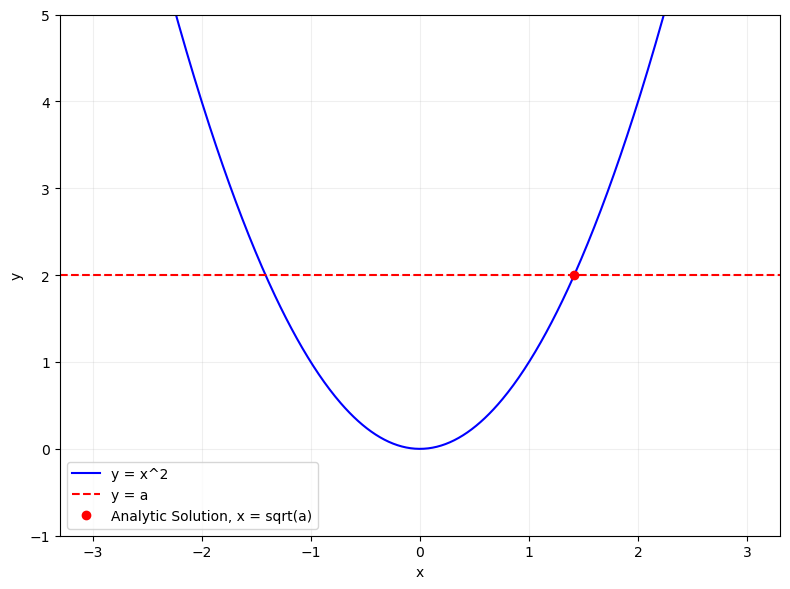

In [6]:
# 1.a)

# Test case for x^2 = a, a = 2.0, solve for positive x, x^2 - 2.0 = 0.0
# Analytically x = +-sqrt(a), symmetric positive/negative, shifted parabola

a = 2.0 # Arbitrary value to evaluate for, line a distance above/below x-axis

def Parabolic(x, a): # Arbitrary Function definition, solutions x = +-sqrt(a)
    if a >= 0:
        return x**2 - a # will return values only for positive sqrts
    else: # error code for linear a value out of domain of funct, no roots
        raise ValueError("Need positive a value, for line x = a \
to be in domain of x^2 parabola")

# Plotted Analytic Curve:
x = np.linspace(-3.0, 3.0, 600)
y = x**2

fig, ax = plt.subplots(figsize=(8,6))
ax.plot(x, y, "-", color="blue",label="y = x^2")
ax.axhline(a, linestyle="--", color="red", label="y = a")
ax.plot(np.sqrt(a), a, "ro", label=rf"Analytic Solution, x = sqrt(a)")
ax.set_ylim(-1.0, 5.0)
ax.set_xlim()
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

# Plot shows intersection of a = 2.0 line, x^2 parabola, with roots at intersect
# Good initial guesses (a, b) would bracket either side of x values for root
# ex.: a = 1, b = 2, or a = 1.25, b = 1.5, by visual inspection

In [7]:
# Bisection Method:

# Target and initial guesses for calling Bisection Method
Target = 2.0
guess_a, guess_b = 1.25, 1.5 # from visually inspecting plot, arbitrary

# Runs methods, returns roots, index #'s at root, history array of convergence
root, index, hist_b = \
Bisection(partial(Parabolic, a=Target), guess_a, guess_b, 100)

# printing output block, self-evident in readout, shows precision limit reached
print(f"Bisection Solution for x^2 = {Target}: {root}, \nInitial guesses: \
({guess_a}, {guess_b}), solution reached after {index} iterations.")
print(f"Analytic Solution  for x^2 = {Target}: {np.sqrt(Target)}")
print(f"Calculated Difference between Bisection and Analytic: \
{root - np.sqrt(Target)}")
print(f"Referenced Machine Precision Epsilon for double float: \
{eps}")
print(f"Bisection Method Difference from Precision Epsilon: \
{abs(root - np.sqrt(Target)) - abs(sys.float_info.epsilon)}")

# Testing/Validation Area(not part of assignment necessarily):

# Error Handling: Invalid Inputs for Bisection Method
# Example of no solutions, a < 0, line would be under the parabola
# TargetNone = (-2.0)
# rootNone = Bisection(partial(Parabolic, a=TargetNone), guess_a, guess_b, 100)
# print(f"Bisection Solution for x^2 = {TargetNone}: {rootNone}, \
# Initial guesses: {guess_a}, {guess_b}")

# Example of guesses that do not bracket the zero (root > (a, b) > root)
# rootNoBracket = Bisection(partial(Parabolic, a=Target), 1.5, 2.0, 100)
# print(f"Bisection Solution for x^2 = {Target}: {rootNoBracket}")

Bisection Solution for x^2 = 2.0: 1.414213562373095, 
Initial guesses: (1.25, 1.5), solution reached after 50 iterations.
Analytic Solution  for x^2 = 2.0: 1.4142135623730951
Calculated Difference between Bisection and Analytic: -2.220446049250313e-16
Referenced Machine Precision Epsilon for double float: 2.220446049250313e-16
Bisection Method Difference from Precision Epsilon: 0.0


In [8]:
# Newton-Raphson Method:
TargetNR = 2.0

# Runs methods, returns roots, index #'s at root, history array of convergence
# Newton-Raphson values:
rootNR, n1, hist_NR = NewtonRaphson(partial(Parabolic, a=TargetNR), 2.0, 100)
# Newton-Raphson AutoGrad values:
rootNRAG, n2, hist_NRAG = \
NewtonRaphsonAutoGrad(partial(Parabolic, a=TargetNR), 2.0, 100)

# printing block for NR/NRAG, showing precision limit matching
print(f"Newton-Raphson Solution         : {rootNR} in {n1} iterations")
print(f"Newton-Raphson AutoGrad Solution: {rootNRAG} in {n2} iterations")
print(f"Analytic Solution  for x^2 = {Target}: {np.sqrt(Target)}")
print(f"Calculated Difference between Newton and Analytic:    \
{rootNR - np.sqrt(Target)}")
print(f"Calculated Difference between NewtonAG and Analytic:  \
{rootNRAG - np.sqrt(Target)}")
print(f"Calculated Difference between Newton and NewtonAG:     \
{rootNR - rootNRAG}")
print(f"Referenced Machine Precision Epsilon for double float: \
{eps}")
print(f"Newton Method Difference from Precision Epsilon  : \
{abs(rootNR - np.sqrt(Target)) - abs(sys.float_info.epsilon)}")
print(f"NewtonAG Method Difference from Precision Epsilon: \
{abs(rootNRAG - np.sqrt(Target)) - abs(sys.float_info.epsilon)}")

# Testing/Validation Area(not part of assignment necessarily):

# Arbitrary test function to validate solutions
# def testfunct(x):
#     return x**2
    
# Examples of syntax, error handling in some cases of no convergence
# print(NewtonRaphson(testfunct, 2.0, 100)) # reaches zero slope near 0, error
# print(NewtonRaphsonAutoGrad(testfunct, 2.0, 100)) # no converge after 100 iter
# print(NewtonRaphsonAutoGrad(testfunct, 2.0, 1000)) # has enough iterations to
# converge to nearly 0, which is sol: x^2 = 0, has multiplicity 2 roots at x = 0

# Working examples
# rootNR, n1 = NewtonRaphson(lambda x: x**2 - 2.0, 2.0, 100)
# rootNRAG, n2 = NewtonRaphsonAutoGrad(lambda x: x**2 - 2.0, 2.0, 100)
# print(f"Newton-Raphson Solution         : {rootNR} in {n1} iterations")
# print(f"Newton-Raphson AutoGrad Solution: {rootNRAG} in {n2} iterations")

Newton-Raphson Solution         : 1.414213562373095 in 6 iterations
Newton-Raphson AutoGrad Solution: 1.414213562373095 in 6 iterations
Analytic Solution  for x^2 = 2.0: 1.4142135623730951
Calculated Difference between Newton and Analytic:    -2.220446049250313e-16
Calculated Difference between NewtonAG and Analytic:  -2.220446049250313e-16
Calculated Difference between Newton and NewtonAG:     0.0
Referenced Machine Precision Epsilon for double float: 2.220446049250313e-16
Newton Method Difference from Precision Epsilon  : 0.0
NewtonAG Method Difference from Precision Epsilon: 0.0


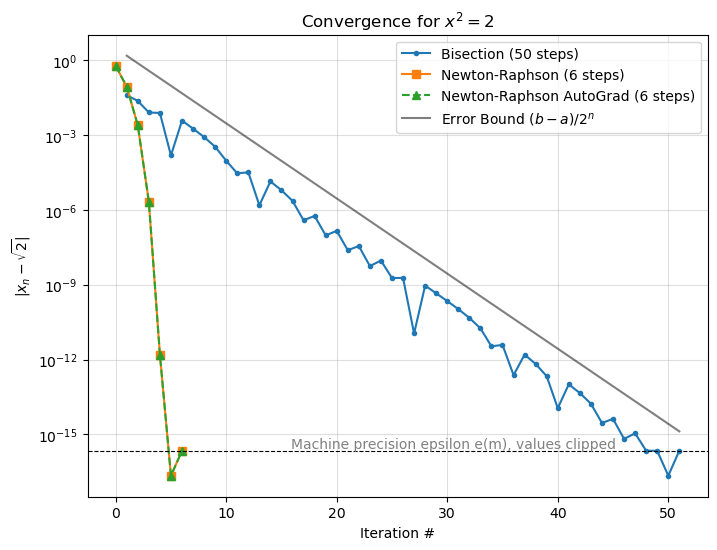

In [9]:
# Log Error plot vs. iteration for each method's error convergence: 
# Difference of (current guess - analytic answer) as function of iteration
# All will return a maximum value between the err at iteration, machine epsilon

# Error Convergence Bisection:

Analytic = np.sqrt(Target) # True solution to compare method against

def errorsB(history):
    errB = np.abs(np.array(history) - Analytic)
    return np.maximum(errB, eps / 10)

# Error Convergence Newton-Raphson:

def errorsNR(history):
    errNR = np.abs(np.array(history) - Analytic)
    return np.maximum(errNR, eps / 10)

# Error Convergence Newton-Raphson AutoGrad:

def errorsNRAG(history):
    errNRAG = np.abs(np.array(history) - Analytic)
    return np.maximum(errNRAG, eps / 10)

fix, ax = plt.subplots(figsize=(8,6))

# Bisection subplot
ax.semilogy(range(1, len(hist_b) + 1), errorsB(hist_b), "o-", ms=3, \
            label=f"Bisection ({index} steps)")

# Newton-Raphson subplot
ax.semilogy(range(len(hist_NR)), errorsNR(hist_NR), "s-", \
                  label=f"Newton-Raphson ({n1} steps)")

# Newton-Raphson AutoGrad subplot
ax.semilogy(range(len(hist_NRAG)), errorsNRAG(hist_NRAG), \
            "^--", label=f"Newton-Raphson AutoGrad ({n2} steps)")

n_array = np.arange(1, len(hist_b) + 1)
ax.semilogy(n_array, 3.0 / 2.0**n_array, "k", alpha=0.5, \
            label=r"Error Bound $(b-a)/2^n$")

ax.axhline(eps, color="black", lw=0.8, ls="--")
ax.text(ax.get_xlim()[1], eps, \
        r"Machine precision epsilon e(m), values clipped                     ",\
        va="bottom", ha="right", color="gray")


ax.set_xlabel("Iteration #")
ax.set_ylabel(r"$|x_n - \sqrt{2}|$")
ax.set_title(r"Convergence for $x^2 = 2$")
ax.grid(alpha=0.4, which="both")
ax.legend()
plt.show()

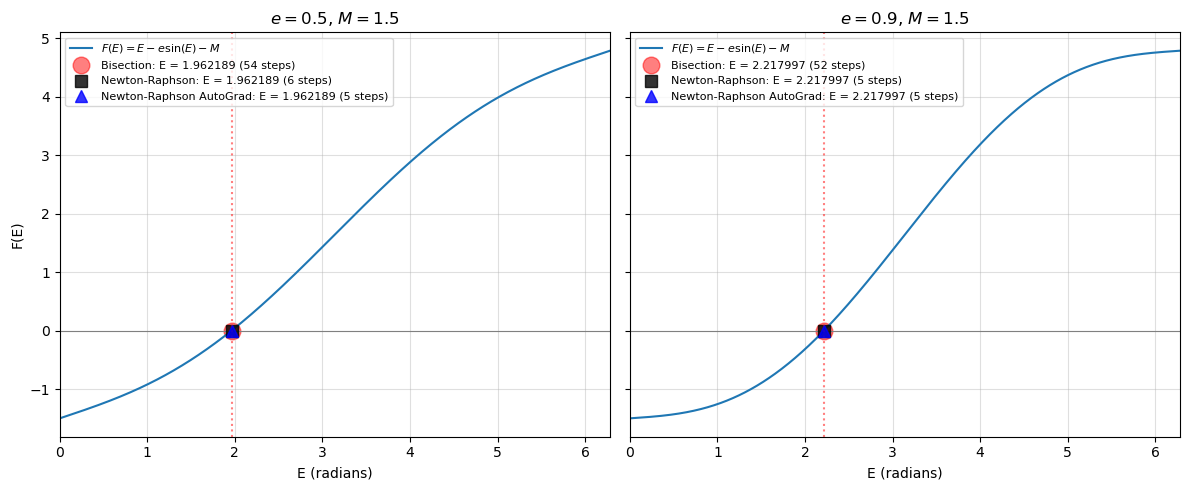

In [10]:
# 1.b)

# Kepler's Equation M = E - e * sin(E)
# For M = Mean Anomoly, E = Eccentric Anomoly, e = Eccentricity of Ellipse
# Try first: M = 1.5, e = 0.5, solve for E in interval 0 ≤ E < 2π
# Try second: M = 1.5, e = 0.9, same interval.

# Kepler's Equation Function Definition:
M = 1.5

# takes params for Eccentricity Anomoly, Eccentricity, Mean Anomoly
def Kepler(E, e, M): 
    return E - e * np.sin(E) - M # returns solution root solution for given vals

# Plotted Analytic Curve with Solutions for E:

cases = [0.5, 0.9] # different e values to try
# unit circle bounds, theta radians, broken up into # of iteration angles
# 1000 chosen arbitrarily, ellipse and circle both about unit circle
# Focii and center of circle are not the same, center of ellipse is at origin
E_grid = np.linspace(0.0, 2.0 * np.pi, 1000) 

figs, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, e in zip(axes, cases): # loop over different e's to test
    F = lambda E, e=e: Kepler(E, e, M) # lock e value in per loop

    # Reuse Solvers to plug in Kepler Function
    
    # Bisection(Kepler):
    root_b, n_b, hist_bKep = Bisection(F, 0.0, 2.0 * np.pi, 100)
    
    # Newton-Raphson(Kepler):
    root_NR, n_nr, hist_NRKep = NewtonRaphson(F, M, 100)
    
    # Newton-Raphson AutoGrad(Kepler):
    root_NRAG, n_nrag, hist_NRAGKep = NewtonRaphsonAutoGrad(F, M, 100)

    ax.plot(E_grid, F(E_grid), label=r"$F(E)=E-e\sin (E)-M$")
    ax.axhline(0.0, color="gray", lw="0.8")
    ax.plot(root_b, 0.0, "ro", ms=12, zorder=1, alpha=0.5,\
            label=f"Bisection: E = {root_b:.6f} ({n_b} steps)")
    ax.plot(root_NR, 0.0, "ks", ms=8, zorder=2, alpha=0.8,\
            label=f"Newton-Raphson: E = {root_NR:.6f} ({n_nr} steps)")
    ax.plot(root_NRAG, 0.0, "b^", ms=8, zorder=3, alpha=0.8,\
            label=f"Newton-Raphson AutoGrad: E = {root_NRAG:.6f} ({n_nrag} steps)")
    ax.axvline(root_b, color="red", ls=":", alpha=0.5)

    ax.set_title(rf"$e = {e}$, $M = {M}$")
    ax.set_xlabel("E (radians)")
    ax.set_xlim(0, 2.0 * np.pi)
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8, loc="upper left")

axes[0].set_ylabel("F(E)")
plt.tight_layout()
plt.show()

In [11]:
# Helper function to collect values of Kepler for all methods:

def errors(history, ref):
    err = np.abs(np.array(history) - ref)
    return np.maximum(err, floor)

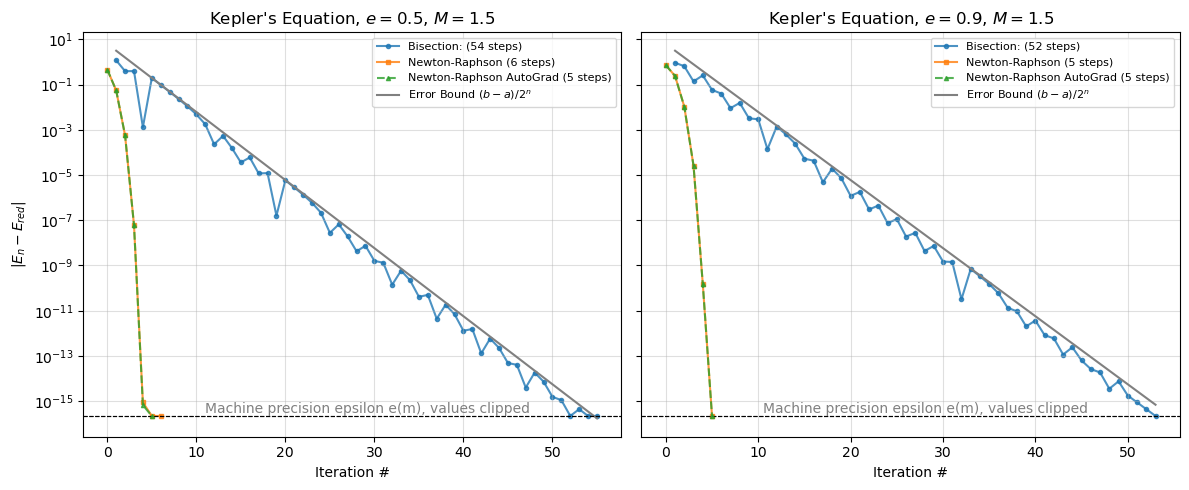

In [12]:
# Plotting Error Convergence, Bisection vs. NR vs. NRAG (Kepler)

floor = eps # eps floor for clipping
cases = [0.5, 0.9] # specific values of e to run
M = 1.5

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, e in zip(axes, cases): # loop over different e's to test
    F = lambda E, e=e: Kepler(E, e, M) # lock e value in per loop

    Err_ref = brentq(F, 0.0, 2.0 * np.pi, xtol=1e-15, rtol=4.0 * eps)
    
    # Reuse Solvers to plug in Kepler Function
    
    # Bisection(Kepler):
    root_b, n_b, hist_bKep = Bisection(F, 0.0, 2.0 * np.pi, 100)
    
    # Newton-Raphson(Kepler):
    root_NR, n_nr, hist_NRKep = NewtonRaphson(F, M, 100)
    
    # Newton-Raphson AutoGrad(Kepler):
    root_NRAG, n_nrag, hist_NRAGKep = NewtonRaphsonAutoGrad(F, M, 100)

    n_arr = np.arange(1, len(hist_bKep) + 1)

    ax.semilogy(n_arr, errors(hist_bKep, Err_ref), "o-", ms=3, zorder=1, \
                alpha=0.8, label=f"Bisection: ({n_b} steps)")
    ax.semilogy(range(len(hist_NRKep)), errors(hist_NRKep, Err_ref), \
                "s-", ms=3, zorder=2, alpha=0.8, \
                label=f"Newton-Raphson ({n_nr} steps)")
    ax.semilogy(range(len(hist_NRAGKep)), errors(hist_NRAGKep, Err_ref), \
                "^--", ms=3, zorder=3, alpha=0.8, \
                label=f"Newton-Raphson AutoGrad ({n_nrag} steps)")
    ax.semilogy(n_arr, 2.0 * np.pi / 2.0**n_arr, color="grey",\
                label=r"Error Bound $(b-a)/2^n$")

    ax.axhline(eps, color="black", lw=0.8, ls="--")
    ax.text(ax.get_xlim()[1], eps, \
        r"Machine precision epsilon e(m), values clipped                     ",\
        va="bottom", ha="right", color="gray")

    ax.axhline(eps, color="k", lw=0.8, ls="--")
    ax.set_title(rf"Kepler's Equation, $e = {e}$, $M = {M}$")
    ax.set_xlabel("Iteration #")
    ax.grid(alpha=0.4, which="both")
    ax.legend(fontsize=8)

axes[0].set_ylabel(r"$|E_n - E_{red}|$")
plt.tight_layout()
plt.show()

In [13]:
# 2. It is frequently required that the Kepler problem be solved to the maximum 
# precision available (i.e. to round-oﬀ) as quickly as possible. 
# Attempt to do this with your Kepler solvers. Use your solvers ﬁnd E for
# 10,000 equally spaced values of M between 0 and 2π for an e = 0.9 orbit. 
# Report the relative performance between the two methods as
# measured in wall clock time. Explain the diﬀerence in performance.

In [14]:
# 2)

# Wall clock time performance difference:

e = 0.9
M_vals = np.linspace(0.0, 2.0 * np.pi, 10000) # 10000 equally spaced vals

def timed_solve(solve, label, repeats=3): # timer wrapper for the methods
    best = np.inf # initial best, keeps track of last best value

    for k in range(repeats): # 3 repeats in function call
        t0 = time.perf_counter() # wall clock start
        solutions = [solve(Mk) for Mk in M_vals] # passed funct(MK) over M vals
        best = min(best, time.perf_counter() - t0) # current - start t, or inf
    solutions = np.array(solutions) # builds solutions array
    # residual errors of all the solutions compared against analytic
    residual = np.max(np.abs(solutions - e * np.sin(solutions) - M_vals))
    print(f"{label:28s} {best:8.4f} s  max residual {residual:.2e}")

    return best

def make_Function(Mk): # function to help do all methods against Kepler function
    return lambda E: E - e * math.sin(E) - Mk

# extra function for NRAG only, has to use np.sin fallback, math.sin cant pass
def make_FunctionAG(Mk): # math.sin instead of np.sin, scalar more efficient
    return lambda E: E - e * anp.sin(E) - Mk
    
# Bisection Method - 10k points, [0.0, 2pi] Bracketed:
t_bisect = timed_solve(lambda Mk: Bisection(make_Function(Mk), \
                    0.0, 2.0 * math.pi, 1200)[0], "Bisection")

# Newton-Raphson Method - 10k points
t_nr =  timed_solve(lambda Mk: NewtonRaphson(make_Function(Mk), \
                    math.pi, 100)[0], "Newton-Raphson")

# Newton-Raphson Method AutoGrad - 10k points
t_nrab =  timed_solve(lambda Mk: NewtonRaphsonAutoGrad(make_FunctionAG(Mk), \
                    math.pi, 100)[0], "Newton-Raphson AutoGrad")

print(f"\nBisection / Newton : {t_bisect / t_nr:.3f}x")
print(f"\nBisection / NewtonAG : {t_bisect / t_nrab:.3f}x")

Bisection                      0.1931 s  max residual 8.88e-16
Newton-Raphson                 0.0825 s  max residual 8.88e-16
Newton-Raphson AutoGrad        4.6250 s  max residual 8.88e-16

Bisection / Newton : 2.342x

Bisection / NewtonAG : 0.042x


In [15]:
# Explanation of the difference in performance:
# 
# From the number of iterative steps alone, Newton only takes 5,6 in either case
# While bisection takes 50+ to arrive at the limit in machine precision diff.
# Even if bisection is relatively less computationally heavy, only taking
# one function eval. per iteration, and Newton-Raphson takes 3 for central 
# difference derivation. Newton-Raphson AutoGrad takes even longer to use, even
# if it has the same or 1 step better convergence over non-AutoGrad, it uses an
# in-built grad(Funct(x)) three times over, so it is generating significantly
# more overhead for every single function call AND iteration step over the two
# other methods. AutoGrad does not scale very efficiently with scalar 1D cases
# but in multi-dimensional cases of Jacobian matrices and overloading those
# same functions and iterations over multiple arrays instead of just a lower
# rank vector operation, it would far exceed both Newton-Raphson and Bisection
# should the AutoGrad really be put through its paces for the applications it 
# was arguably designed for. It will be more general in terms of being able to
# tackle anything from scalar up to multi-dimentional out of the package, with
# no cumbersome partial differential gradient functions to hand-construct for
# the other methods, even if it suffers efficiency losses in the lower ranked
# scalar walks. Bisection is less expensive, but requires a longer walk than
# the two Newton-Raphsons, so it is kind of a balance between the two, but with
# much more limited functionality. And the NRAG method I used needed to use
# an anp.sin instead of math.sin inside of it to be functional, which added
# an extra layer of overhead on top of by it not using the fastest intrinsics

In [16]:
# 3. When simulating the growth of structure in the Universe, it is usually
# required to calculate the expansion factor of the universe, a, at arbitrary
# cosmic time, t. These are related by

# t = ∫0->a [da′ / (a′ * H(a′))]

# where H(a) is given by the Friedman equation (assuming “natural units”):

# H^2(a) = [(8π / 3) * ((Ω_M / a^3) + (Ω_R / a^4) + Ω_Λ + (Ω_K / a^2))]

# where Ω_M, Ω_R, Ω_Λ and Ω_K are cosmological parameters for the density
# of matter, radiation, Dark Energy and curvature, respectively. 
# Use your Newton solver to ﬁnd a given t, evaluating the integral using
# a numerical quadratures package, and plot a vs. t for 100 values of
# t equally spaced between 0 and 0.33 using the Planck values for the
# cosmology parameters: 
# Ω_M = 0.321, Ω_R = 5.5 × 10^−5, Ω_Λ = 0.679, and Ω_K = −0.058.


In [17]:
# 3)

# Newton-Raphson Integration + Quadratures Package Solution for given t:
# By the equation above, the a terms under the denominator pose a risk for zeros
# Should use 1/aH(a) form instead, so as a->0, the entire integrand does
# instead of resulting in an undefined discontinuity.

Om_M, Om_R, Om_L, Om_K = 0.321, 5.5e-5, 0.679, -0.058
c = 8.0 * math.pi / 3.0

# F'(a) = dt/da reciprocal integrand 1/aH(a) for easier calcs, calculus identity
def integrand(ap): # restructured H^2(a) to 1/aH(a), helper function to t_cosmic
    return ap / math.sqrt(c * (Om_R + Om_M*ap + Om_K*ap**2 + Om_L*ap**4))

def t_cosmic(a): # t(a) integral from 0 to a, with epsilon tolerances abs./rel.
    val, err = quad(integrand, 0.0, a, epsabs=1e-14, epsrel=1e-13)
    return val # returns value of integrand over time integration bounds

#  Newton-Raphson Reworked for Cosmology

# Takes params for arbitrary function, arbitrary x, and max iterations to run
def NRCosmo(Funct, dFunct, x_0, max_iteration=100):
    x = float(x_0)
    history = [x] # keeps array of values of towards convergence at index
    dx_prev = np.inf # similar previous derivative init. like above
    
    for j in range(max_iteration): # main loop over selected # of iterations
        Fx = Funct(x) # F(x) given function evaluated at given x
        if Fx == 0.0:
            return x, j, history # returns root solution, iter, history
            
        Fp = dFunct(x) # F'(x), first derivative of function at given x
        if Fp == 0.0:
            raise ZeroDivisionError("Zero Slope, starting x won't converge")
            
        dx = Fx / Fp # setting 2nd term for x_n - (F(x_n) / F'(x_n)) 
        x -= dx # iteration step applied
        history.append(x) # tabulates the history of x vals over iterations
        
        # strict test, OR at the noise floor (step tiny and no longer shrinking)
        at_floor = abs(dx) >= abs(dx_prev) and abs(dx) < 1e-6 * max(abs(x), 1.0)
        if abs(dx) <= eps * abs(x) or at_floor:
            return x, j + 1, history

        dx_prev = abs(dx) # sets new last dx each iteration to keep track

    # if x does not converge to a root within machine limits of precision
    # raise error code displaying convergence did not happen in # of iterations
    raise RuntimeError(f"No convergence after {max_iteration} iteration steps")

# Setting up regularly spaced t values, a array of zeros to match data size/type
t_vals = np.linspace(0.0, 0.33, 100) # (0.0, 0.33) not including end points
a_vals = np.zeros_like(t_vals) # creates zero'd out array same size as time arr.
n_iters = np.zeros(len(t_vals), dtype=int) # integer iteration, length of arrays

for k, t in enumerate(t_vals): # over all times, find where a = 0, or iterates
    if t == 0.0:
        continue # when a = 0 exactly
    a0 = (1.5 * math.sqrt(c * Om_M) * t)**(2.0/3.0)
    # if a value is not found to be a root, will update and iterate over all t
    a_vals[k], n_iters[k], _ = NRCosmo(lambda aa: t_cosmic(aa) - t, integrand, \
                                      a0, 100) # tabulates a's at each index

# Diagnostic Checks
resid = max(abs(t_cosmic(a) - t) for a, t in zip(a_vals, t_vals))
t_today = t_cosmic(1.0)                          # time at a = 1
print(f"max |t(a) - t| = {resid:.2e}, max iterations = {n_iters.max()}")
print(f"t(a=1) = {t_today:.5f}")

max |t(a) - t| = 1.11e-16, max iterations = 6
t(a=1) = 0.33712


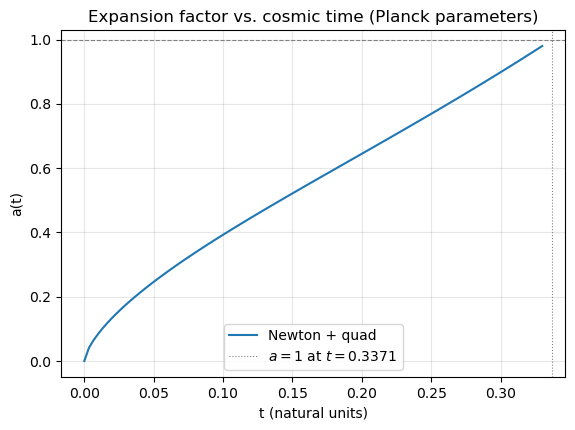

In [18]:
# Plot of a vs. t, 100 equally spaced t values, 0.0 < t < 0.33 (open interval)
# for Ω_M = 0.321, Ω_R = 5.5 × 10^−5, Ω_Λ = 0.679, and Ω_K = −0.058.

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(t_vals, a_vals, label="Newton + quad")
ax.axhline(1.0, color="gray", ls="--", lw=0.8)
ax.axvline(t_today, color="gray", ls=":", lw=0.8, label=rf"$a=1$ at $t={t_today:.4f}$")
ax.set_xlabel("t (natural units)")
ax.set_ylabel("a(t)")
ax.set_title("Expansion factor vs. cosmic time (Planck parameters)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()